# SIPNET Ecosystem Carbon and Water Fluxes: Active Subspaces of the Fer et al. (2018) Calibration Parameters in a Substitute Set-up

**Substitute set-up, not the paper's runs:** the Niwot Ridge meteorological driver that ships with SIPNET (instead of the paper's Bartlett Experimental Forest driver) and PEcAn's template values for every SIPNET parameter the paper did not calibrate (instead of its Bartlett trait meta-analysis values).

Based on: __Istem Fer__¹, __Ryan Kelly__², __Paul R. Moorcroft__³, __Andrew D. Richardson__⁴˒⁵, __Elizabeth M. Cowdery__¹, and __Michael C. Dietze__¹, "Linking big models to big data: efficient ecosystem model calibration through Bayesian model emulation", *Biogeosciences* 15, 5801–5830, 2018.

¹ Department of Earth and Environment, Boston University, Boston, MA, USA
² RK Analytics, Durham, NC, USA
³ Department of Organismic and Evolutionary Biology, Harvard University, Cambridge, MA, USA
⁴ School of Informatics, Computing and Cyber Systems, Northern Arizona University, Flagstaff, AZ, USA
⁵ Center for Ecosystem Science and Society, Northern Arizona University, Flagstaff, AZ, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

Fer et al. (2018) calibrated eight physiological and soil parameters of the SIPNET ecosystem model (plus a likelihood bias term) against flux-tower data from Bartlett Experimental Forest with a Gaussian-process emulator. **In a substitute set-up**, we ran the compiled SIPNET code (v2.2.0) at 1000 Latin hypercube samples of the paper's uniform priors, with finite-difference gradients of three two-year totals, on the Niwot Ridge (Colorado, 2004–2005) meteorological driver that ships with SIPNET and with PEcAn's generic template values for every parameter the paper did not calibrate, because the paper's Bartlett driver (the tower data are on AmeriFlux, but were not reachable from our build container and are not packaged as a SIPNET driver) and its Bartlett trait meta-analysis values were not available; in this colder, drier set-up 902 of the 1000 samples are net carbon sources over the two years. Total evapotranspiration has a clear one-dimensional active subspace aligned with the soil water holding capacity, whereas cumulative net ecosystem exchange (NEE) has a dominant direction (the optimum photosynthesis temperature) but needs about four dimensions for an accurate summary.

## Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs $\mathbf x\in[-1,1]^m$ with density $\rho$, the matrix $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$ measures how $f$ changes, on average, along each direction. A large gap after the $n$-th eigenvalue means that $f$ varies mostly along the first $n$ eigenvectors $\mathbf W_1$, so $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$; a *sufficient summary plot* of $f$ against $\mathbf W_1^T\mathbf x$ shows this. Here $\mathbf C$ is estimated by Monte Carlo from sampled gradients. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

## The model

**SIPNET** (Simplified PnET; Braswell et al. 2005, Sacks et al. 2006) is a lumped ecosystem carbon and water model with pools for wood, leaves, soil carbon, litter, snow and soil water, driven by air and soil temperature, PAR, precipitation, vapor pressure deficit (VPD) and wind. The eight parameters studied enter as follows (SIPNET v2.2.0 source, `src/sipnet/sipnet.c`):

- Gross photosynthesis is $A = A_{\max}\, D_T\, D_{\rm VPD}\, D_{\rm light}\, D_{\rm water}\cdot\text{LAI}$, with $D_T = (T_{\max}-T)(T-T_{\min})/((T_{\max}-T_{\min})/2)^2$ clipped at 0 and $T_{\max} = 2\,T_{\rm opt} - T_{\min}$ (`psnTOpt`, also the reference temperature of foliar respiration, $R_{\rm fol}\propto Q_{10,\rm veg}^{(T-T_{\rm opt})/10}$); $D_{\rm VPD} = \max(0, 1 - K_{\rm VPD}\,{\rm VPD}^2)$ (`dVpdSlope`); $D_{\rm light}$ through $1-2^{-I/{\rm PAR}_{1/2}}$ integrated over canopy layers (`halfSatPar`); $D_{\rm water}$ from the water available in a soil bucket of capacity `soilWHC`.
- Heterotrophic soil respiration is $R_h = K_{\rm soil}\, C_{\rm soil}\, Q_{10}^{T_{\rm soil}/10}\, f(W)$ (`baseSoilResp`, `soilRespQ10`), all year. **This differs from the paper's SIPNET build:** the 2018 PEcAn set-up also tied SIPNET's cold-season soil respiration to the two calibrated soil parameters (`baseSoilRespCold` = 0.25 × `baseSoilResp`, `soilRespQ10Cold` = `soilRespQ10`; PEcAn `write.configs.SIPNET.R`, whose comment says these were the assumptions of the emulator paper and matter only when SIPNET's seasonal soil respiration is on, which the paper does not state). SIPNET v2 removed those cold-season parameters, so they have no counterpart here.
- Leaves gain `leafGrowth` g C m⁻² at leaf-on (growing-degree-day trigger) and lose carbon at rate `leafTurnoverRate` year⁻¹, plus all remaining leaves at leaf-off (the deciduous setting of PEcAn's template).
- NEE $= R_a + R_h - A$ (positive = carbon source). Evapotranspiration is transpiration (coupled to $A$ through water-use efficiency) plus evaporation and snow sublimation.

**Set-up (substitute, not the paper's).** SIPNET v2.2.0-11 (commit `c3479bd`), compiled with gcc 13.3; parameter file = PEcAn's SIPNET template (`template.param_v2`) with the paper's initial pools (Table A1: wood 9600 g C m⁻², LAI 0, litter 200 g C m⁻², soil 1600 g C m⁻²); driver = the Niwot Ridge file of SIPNET's smoke test, cut to 2004-01-01 to 2005-12-31 (1462 half-day steps). The paper ran the same model through PEcAn at Bartlett for 2005–2006 at half-hourly steps, with its other parameters from PEcAn's trait meta-analysis. The Bartlett tower data are on AmeriFlux but were not reachable from our build container and are not packaged as a SIPNET driver in any repository, and the meta-analysis values live in PEcAn's BETYdb database; so **this is a hybrid test case**: the paper's eight priors and its four Bartlett initial pools, every other parameter at PEcAn's generic deciduous template value, and a subalpine climate. It is not a reproduction of the paper's runs. `DATA.md` has the details.

**Quantities of interest** (2004–2005 totals): cumulative NEE (g C m⁻²), total evapotranspiration ET (mm; approximately a linear function of the mean latent heat flux LE, the paper's second data stream, since SIPNET's ET also counts snow sublimation), and total gross primary production GPP (g C m⁻², stored but only summarized here). The paper's QoIs were likelihood statistics against Bartlett observations; the multiplicative soil-respiration bias $k$ enters only that likelihood, so it is not an input here and $m = 8$.

**Inputs**: independent uniform priors of the paper's Table A2.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import active_subspaces as ac

SEED = 514            # the one seed for every rng= below
t_start = time.perf_counter()

# Inputs: SIPNET name, PEcAn trait name in Fer et al. (2018), units, lower, upper (Table A2)
INPUTS = [
    ('baseSoilResp',     'som_respiration_rate', '1/yr',               0.001, 0.3),
    ('soilRespQ10',      'soil_respiration_Q10', '-',                  1.4,   3.0),
    ('soilWHC',          'soilWHC',              'cm',                 0.1,   36.0),
    ('halfSatPar',       'half_saturation_PAR',  'Einsteins/(m2 day)', 4.0,   27.0),
    ('dVpdSlope',        'dVPDSlope',            '1/kPa',              0.01,  0.25),
    ('leafGrowth',       'leafGrowth',           'g C/m2',             0.0,   252.0),
    ('psnTOpt',          'psnTOpt',              'degC',               5.0,   40.0),
    ('leafTurnoverRate', 'leaf_turnover_rate',   '1/yr',               0.03,  6.0),
]
names = [r[0] for r in INPUTS]
lower = np.array([r[3] for r in INPUTS])
upper = np.array([r[4] for r in INPUTS])
labels = [r'$K_{soil}$', r'$Q_{10}$', r'$WHC$', r'$PAR_{1/2}$', r'$K_{VPD}$',
          r'$\Delta C_{leaf}$', r'$T_{opt}$', r'$K_{leaf}$']
space = ac.Uniform(lower, upper, names=names)   # v1 maps each input to [-1, 1]

rows = ['| SIPNET name | PEcAn name (paper) | units | prior (Table A2) |', '|---|---|---|---|']
rows += [f'| `{n}` | {p} | {u} | U({a:g}, {b:g}) |' for n, p, u, a, b in INPUTS]
display(Markdown('\n'.join(rows)))
k_post = 0.1   # brute-force posterior mean of som_respiration_rate, Table A2: N(0.1, 0.009)
print(f'soil carbon turnover time 1/k at the posterior mean: {1 / k_post:.0f} days if k is per day, '
      f'{1 / k_post:.0f} years if k is per year')

| SIPNET name | PEcAn name (paper) | units | prior (Table A2) |
|---|---|---|---|
| `baseSoilResp` | som_respiration_rate | 1/yr | U(0.001, 0.3) |
| `soilRespQ10` | soil_respiration_Q10 | - | U(1.4, 3) |
| `soilWHC` | soilWHC | cm | U(0.1, 36) |
| `halfSatPar` | half_saturation_PAR | Einsteins/(m2 day) | U(4, 27) |
| `dVpdSlope` | dVPDSlope | 1/kPa | U(0.01, 0.25) |
| `leafGrowth` | leafGrowth | g C/m2 | U(0, 252) |
| `psnTOpt` | psnTOpt | degC | U(5, 40) |
| `leafTurnoverRate` | leaf_turnover_rate | 1/yr | U(0.03, 6) |

soil carbon turnover time 1/k at the posterior mean: 10 days if k is per day, 10 years if k is per year


`baseSoilResp` is listed in the paper's Table A3 in day⁻¹. We treat that unit as an error in the paper: SIPNET reads the parameter in year⁻¹ (it divides by 365 internally), PEcAn passes the trait through unchanged with the comment "units = 1/year", and the paper's brute-force posterior mean would give a soil-carbon turnover time of 10 days if read per day (10 years per year, printed above). So the prior U(0.001, 0.3) is applied in year⁻¹ here. All inputs are uniform, so every input is scaled the same way: linearly from its prior interval to $[-1,1]$.

## Load the data

`generate_data.py` wrote three CSV files with the compiled SIPNET binary (see `DATA.md`); the notebook does not need SIPNET. Gradients are with respect to the physical inputs, column $8i+j$ for QoI $i$ and input $j$. We also load the driver to report its totals.

In [2]:
X = np.loadtxt('inputs.csv', delimiter=',')          # (M, 8) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')         # (M, 3) cum_nee, total_et, total_gpp
G = np.loadtxt('gradients.csv', delimiter=',')       # (M, 24) physical gradients
clim = np.loadtxt('niwot_2004_2005.clim')            # (1462, 14) SIPNET driver, old format
qois = ['cum_nee', 'total_et', 'total_gpp']
units = ['g C m$^{-2}$', 'mm', 'g C m$^{-2}$']
grads = {q: G[:, 8 * i:8 * i + 8] for i, q in enumerate(qois)}
f = {q: F[:, i] for i, q in enumerate(qois)}
M, m = X.shape
print(f'X {X.shape}, F {F.shape}, G {G.shape}, driver {clim.shape}')
print(f'inputs inside the prior box: {np.all((X >= lower) & (X <= upper))}')
precip = clim[:, 8].sum()
print(f'driver 2004-2005: precipitation {precip:.0f} mm, mean air temperature '
      f'{np.average(clim[:, 5], weights=clim[:, 4]):.2f} degC')
for q in qois:
    print(f'{q:9s}: min {f[q].min():9.2f}  median {np.median(f[q]):9.2f}  max {f[q].max():9.2f}')
print(f'samples with net uptake (cum_nee < 0): {(f["cum_nee"] < 0).sum()} of {M}; '
      f'net carbon sources (cum_nee > 0): {(f["cum_nee"] > 0).sum()} of {M} ({(f["cum_nee"] > 0).mean():.1%})')
BARTLETT_PRECIP = 1300    # mm per year at the paper's site (Fer et al. 2018, App. A1)
print(f'driver precipitation per year: {precip / 2:.0f} mm (paper site, Bartlett: about {BARTLETT_PRECIP} mm)')

X (1000, 8), F (1000, 3), G (1000, 24), driver (1462, 14)
inputs inside the prior box: True
driver 2004-2005: precipitation 1494 mm, mean air temperature 2.25 degC
cum_nee  : min   -868.49  median    674.75  max   2104.52
total_et : min    722.46  median   1381.83  max   1611.98
total_gpp: min      0.03  median    693.62  max   2380.44
samples with net uptake (cum_nee < 0): 98 of 1000; net carbon sources (cum_nee > 0): 902 of 1000 (90.2%)
driver precipitation per year: 747 mm (paper site, Bartlett: about 1300 mm)


**Physical-meaning checks.** No input is outside its prior. Total ET exceeds the two-year precipitation in some samples, which is possible only by drawing on the initial soil water ($0.5\times$`soilWHC`) and snow (1 cm). The cell below counts samples that would violate this water balance, and samples whose canopy never develops (two-year GPP below 10 g C m⁻²); these are kept, since they are what the model does at those parameters.

**The regime of this set-up.** The substitute driver averages 2.25 °C and 747 mm of precipitation per year, against about 1300 mm per year at the paper's moist Bartlett site. In this regime 902 of the 1000 samples (90.2 %) are net carbon sources over the two years (median cumulative NEE 674.75 g C m⁻²). The subspaces below describe this regime; they should not be transferred to the paper's site, least of all for NEE.

In [3]:
w0 = 0.5 * X[:, 2] * 10 + 10           # initial soil water + snow, mm
print(f'ET > precipitation: {(f["total_et"] > precip).sum()}; '
      f'ET > precipitation + initial water: {(f["total_et"] > precip + w0).sum()}')
low = f['total_gpp'] < 10
print(f'GPP < 10 g C/m2: {low.sum()} samples; their soilWHC range {X[low, 2].min():.2f}-'
      f'{X[low, 2].max():.2f} cm, psnTOpt range {X[low, 6].min():.1f}-{X[low, 6].max():.1f} degC')

ET > precipitation: 144; ET > precipitation + initial water: 0
GPP < 10 g C/m2: 26 samples; their soilWHC range 2.84-32.42 cm, psnTOpt range 5.4-39.9 degC


## Estimate the subspaces

SIPNET is cheap (about 20 ms per two-year run) and piecewise smooth (the clipping in $D_T$ and $D_{\rm VPD}$, the soil-water bucket, and snow give kinks), so we use **gradients**: central finite differences in the normalized inputs with step $h = 10^{-3}$ (one-sided second-order differences within $h$ of a bound), 17 runs per sample. `DATA.md` gives a step study and an independent check at random samples; the stencils meet the most kinks at small `soilWHC`, so the cell after the eigenvalue table checks that region with smaller steps and measures the effect on the eigenvalues. The estimator is v1's gradient-based `'as'`, with 500 bootstrap replicates.

In [4]:
subs = {}
for q in qois:
    s = ac.active_subspace(space=space, grads=grads[q], estimator='as', nboot=500, rng=SEED)
    # sign: f increases along w1
    subs[q] = ac.orient(s, by='covariance', X=X, f=f[q], columns=2)

print(' QoI        n_evg  lambda_1     l1/l2   l2/l3   l3/l4   l4/l5')
for q in qois:
    lam = subs[q].eigenvalues
    k_evg = ac.dimension_criterion(subs[q], rule='evg')[2]
    print(f' {q:9s}  {k_evg:5d}  {lam[0]:.3e}  {lam[0]/lam[1]:6.2f}  {lam[1]/lam[2]:6.2f}  '
          f'{lam[2]/lam[3]:6.2f}  {lam[3]/lam[4]:6.2f}')
lam_et = subs['total_et'].eigenvalues
print(f'total_et eigenvalues 7 and 8: {lam_et[6]:.1e}, {lam_et[7]:.1e} '
      '(baseSoilResp and soilRespQ10 do not affect ET)')

 QoI        n_evg  lambda_1     l1/l2   l2/l3   l3/l4   l4/l5
 cum_nee        1  1.823e+06    3.67    1.16    3.09    4.61
 total_et       1  8.269e+05   51.94    2.83    7.64   24.20
 total_gpp      1  1.951e+06    2.66    1.32    6.94   20.81
total_et eigenvalues 7 and 8: 1.4e-23, 0.0e+00 (baseSoilResp and soilRespQ10 do not affect ET)


In [5]:
# Step check at small soilWHC: fd_check_soilWHC.csv (generate_data.py --fd-check) holds
# d f / d soilWHC with steps 3e-5 and 1e-5 at every sample with normalized soilWHC < -0.8.
chk = np.loadtxt('fd_check_soilWHC.csv', delimiter=',')
r = chk[:, 0].astype(int)
whc = chk[:, 1]
half = (upper - lower) / 2
print(f'{len(r)} samples with soilWHC < {lower[2] + 0.1 * (upper[2] - lower[2]):.2f} cm '
      f'({(whc < 0.6).sum()} below 0.6 cm)')
print('relative 2-norm error of the stored normalized gradient (step 1e-3) when its soilWHC component')
print('is replaced by the step-3e-5 value; last column: step 1e-5 against step 3e-5')
for i, q in enumerate(qois):
    g = grads[q][r] * half
    ref, ref1 = g.copy(), g.copy()
    ref[:, 2], ref1[:, 2] = chk[:, 2 + i] * half[2], chk[:, 5 + i] * half[2]
    err = np.linalg.norm(g - ref, axis=1) / np.linalg.norm(ref, axis=1)
    e1 = np.linalg.norm(ref1 - ref, axis=1) / np.linalg.norm(ref, axis=1)
    print(f'  {q:9s}: median {np.median(err):.1e}, max {err.max():.3f} (soilWHC {whc[err.argmax()]:.2f} cm), '
          f'> 1 %: {(err > 0.01).sum()}, max for soilWHC >= 0.6 cm {err[whc >= 0.6].max():.1e}; '
          f'1e-5 vs 3e-5: max {e1.max():.1e}')
print('eigenvalue ratios l1/l2, l2/l3, l3/l4 and |w1 . w1_new| with the step-3e-5 soilWHC derivatives:')
for i, q in enumerate(qois):
    Gs = grads[q].copy()
    Gs[r, 2] = chk[:, 2 + i]
    lam_s, W_s = np.linalg.eigh((Gs * half).T @ (Gs * half) / M)
    lam_s, W_s = lam_s[::-1], W_s[:, ::-1]
    lam = subs[q].eigenvalues
    print(f'  {q:9s}: stored {lam[0]/lam[1]:.3f}, {lam[1]/lam[2]:.3f}, {lam[2]/lam[3]:.3f}; '
          f'replaced {lam_s[0]/lam_s[1]:.3f}, {lam_s[1]/lam_s[2]:.3f}, {lam_s[2]/lam_s[3]:.3f}; '
          f'|w1 . w1_new| = {abs(subs[q].W[:, 0] @ W_s[:, 0]):.6f}')

100 samples with soilWHC < 3.69 cm (14 below 0.6 cm)
relative 2-norm error of the stored normalized gradient (step 1e-3) when its soilWHC component
is replaced by the step-3e-5 value; last column: step 1e-5 against step 3e-5
  cum_nee  : median 8.7e-04, max 0.137 (soilWHC 0.48 cm), > 1 %: 12, max for soilWHC >= 0.6 cm 2.0e-02; 1e-5 vs 3e-5: max 8.1e-03
  total_et : median 2.2e-04, max 0.028 (soilWHC 2.80 cm), > 1 %: 16, max for soilWHC >= 0.6 cm 2.8e-02; 1e-5 vs 3e-5: max 1.9e-03
  total_gpp: median 2.3e-04, max 0.035 (soilWHC 0.48 cm), > 1 %: 6, max for soilWHC >= 0.6 cm 8.7e-03; 1e-5 vs 3e-5: max 6.8e-03
eigenvalue ratios l1/l2, l2/l3, l3/l4 and |w1 . w1_new| with the step-3e-5 soilWHC derivatives:
  cum_nee  : stored 3.666, 1.162, 3.089; replaced 3.675, 1.161, 3.088; |w1 . w1_new| = 1.000000
  total_et : stored 51.941, 2.833, 7.641; replaced 52.007, 2.833, 7.641; |w1 . w1_new| = 1.000000
  total_gpp: stored 2.661, 1.316, 6.942; replaced 2.666, 1.315, 6.937; |w1 . w1_new| = 1.000000


At the 100 samples with `soilWHC` < 3.69 cm, the stored step ($h = 10^{-3}$) is accurate at most samples (median relative error of the NEE gradient 8.7e-04) but not everywhere: the NEE gradient is off by more than 1 % at 12 samples, by up to 0.137 at `soilWHC` = 0.48 cm, and by at most 2.0e-02 at `soilWHC` ≥ 0.6 cm; for ET and GPP the maxima are 0.028 and 0.035. The step-$3\times10^{-5}$ reference is itself uncertain where kinks are densest (step $10^{-5}$ differs from it by up to 8.1e-03 for NEE). Replacing the soilWHC derivatives at these 100 samples changes the eigenvalue ratios very little (cumulative NEE $\lambda_1/\lambda_2$ 3.666 → 3.675, total ET 51.941 → 52.007) and leaves $\mathbf w_1$ unchanged ($|\mathbf w_1^T\mathbf w_1^{\rm new}|$ = 1.000000), so this finite-difference error does not affect the results below, and we keep the shipped gradients. The other gradient components are checked in `DATA.md`.

## Results: cumulative NEE

### Eigenvalues and subspace errors

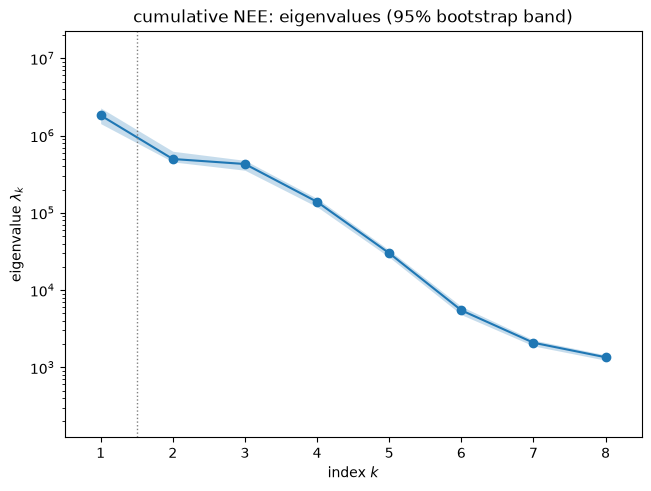

In [6]:
q = 'cum_nee'
s = subs[q]
fig, ax = ac.plotting.plot_eigenvalues(s)
ax.set_title('cumulative NEE: eigenvalues (95% bootstrap band)')
fig

lambda_1 = 1.823e+06 (95% interval 1.426e+06 to 2.277e+06); lambda_2 = 4.971e+05 (4.560e+05 to 6.259e+05); lambda_3 = 4.280e+05 (3.555e+05 to 4.774e+05)


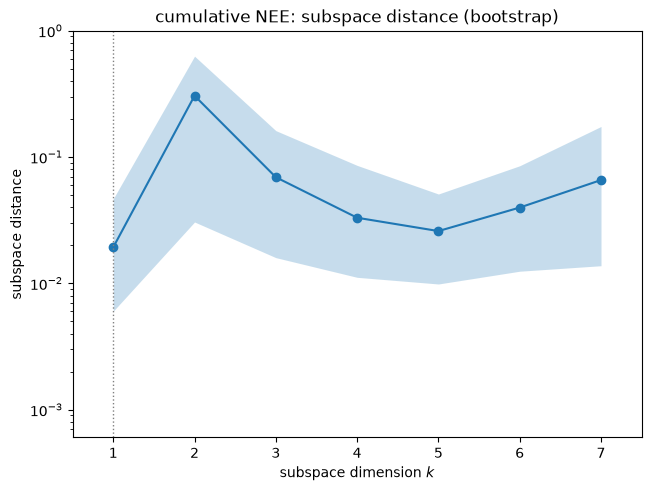

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(s)
ax.set_title('cumulative NEE: subspace distance (bootstrap)')
lo, hi = ac.bootstrap_interval(s.bootstrap_eigenvalues)
print(f'lambda_1 = {s.eigenvalues[0]:.3e} (95% interval {lo[0]:.3e} to {hi[0]:.3e}); '
      f'lambda_2 = {s.eigenvalues[1]:.3e} ({lo[1]:.3e} to {hi[1]:.3e}); '
      f'lambda_3 = {s.eigenvalues[2]:.3e} ({lo[2]:.3e} to {hi[2]:.3e})')
fig

The first eigenvalue of the NEE matrix is only 3.67 times the second, and the second and third are close (ratio 1.16, with overlapping bootstrap intervals), so the second and third eigenvectors are poorly determined individually; the gap rule still picks $n = 1$. The next clear drops come after $\lambda_3$ (ratio 3.09) and $\lambda_4$ (4.61).

### Eigenvectors

w1: baseSoilResp +0.139, soilRespQ10 +0.021, soilWHC -0.046, halfSatPar +0.065, dVpdSlope +0.015, leafGrowth +0.063, psnTOpt -0.985, leafTurnoverRate -0.019
activity scores (all 8 eigenpairs), fraction of total: baseSoilResp 0.081, soilRespQ10 0.002, soilWHC 0.152, halfSatPar 0.026, dVpdSlope 0.006, leafGrowth 0.122, psnTOpt 0.607, leafTurnoverRate 0.004
samples with psnTOpt < 10 degC: 14.3% of samples, 55.3% of the summed squared normalized gradient
mean dNEE/dpsnTOpt = -25.4 = -13.4 (through GPP) + -12.0 (through ecosystem respiration, 47% of the mean slope)
  psnTOpt < 10 : mean dNEE/dpsnTOpt  -144.8 =  -150.4 (GPP) +    5.6 (Reco)
  psnTOpt >= 10: mean dNEE/dpsnTOpt    -5.5 =     9.4 (GPP) +  -14.9 (Reco)
psnTOpt bin (degC): mean GPP, mean Reco (g C m-2)
   5- 8: n =  85, GPP   184, Reco  1553
   8-10: n =  58, GPP   682, Reco  1686
  10-12: n =  57, GPP   918, Reco  1657
  12-20: n = 228, GPP   893, Reco  1471
  20-30: n = 287, GPP   761, Reco  1295
  30-40: n = 285, GPP   617, Re

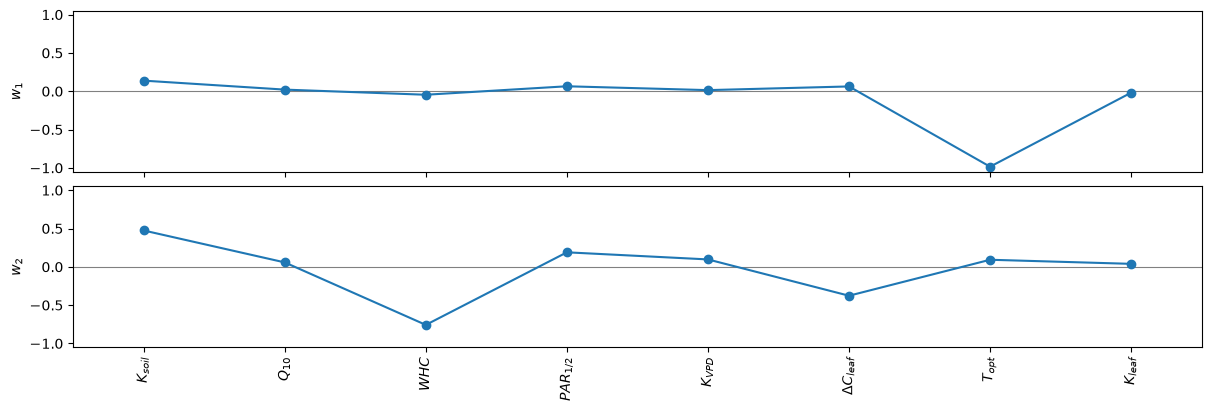

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(s, indices=[0, 1], labels=labels, figsize=(12, 4))
w1 = s.W[:, 0]
print('w1:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(names, w1)))
act = ac.activity_scores(s, n=m)
act_nee = act / act.sum()
print('activity scores (all 8 eigenpairs), fraction of total:',
      ', '.join(f'{n} {a:.3f}' for n, a in zip(names, act_nee)))
e = (grads[q] * (upper - lower) / 2) ** 2
cold = X[:, 6] < 10
print(f'samples with psnTOpt < 10 degC: {cold.mean():.1%} of samples, '
      f'{e[cold].sum() / e.sum():.1%} of the summed squared normalized gradient')
# NEE = Reco - GPP, so dNEE/dpsnTOpt = dReco/dpsnTOpt - dGPP/dpsnTOpt (physical units, g C m-2 per degC)
d_nee, d_gpp = grads['cum_nee'][:, 6], grads['total_gpp'][:, 6]
d_reco = d_nee + d_gpp
reco = f['cum_nee'] + f['total_gpp']
print(f'mean dNEE/dpsnTOpt = {d_nee.mean():.1f} = {-d_gpp.mean():.1f} (through GPP) + {d_reco.mean():.1f} '
      f'(through ecosystem respiration, {d_reco.mean() / d_nee.mean():.0%} of the mean slope)')
for lab, k in [('psnTOpt < 10', cold), ('psnTOpt >= 10', ~cold)]:
    print(f'  {lab:13s}: mean dNEE/dpsnTOpt {d_nee[k].mean():7.1f} = {-d_gpp[k].mean():7.1f} (GPP) + {d_reco[k].mean():6.1f} (Reco)')
print('psnTOpt bin (degC): mean GPP, mean Reco (g C m-2)')
edges = [5, 8, 10, 12, 20, 30, 40]
for a, b in zip(edges[:-1], edges[1:]):
    k = (X[:, 6] >= a) & (X[:, 6] < b)
    print(f'  {a:2d}-{b:2d}: n = {k.sum():3d}, GPP {f["total_gpp"][k].mean():5.0f}, Reco {reco[k].mean():5.0f}')
fig

The first eigenvector is almost the (negative) `psnTOpt` axis (component −0.985), and `psnTOpt` carries a fraction 0.607 of the total activity score, followed by `soilWHC` (0.152), `leafGrowth` (0.122) and `baseSoilResp` (0.081). The reason is in the gradients. SIPNET's photosynthesis window is $T_{\min} < T < 2T_{\rm opt} - T_{\min}$ with $T_{\min} = 2$ °C, so a low optimum temperature closes the window on warm days: mean two-year GPP is 918 g C m⁻² for `psnTOpt` in 10–12 °C, 682 in 8–10 °C and 184 in 5–8 °C, so photosynthesis collapses below about 10 °C and NEE rises steeply. The 14.3 % of samples with `psnTOpt` < 10 °C contribute 55.3 % of the summed squared gradient, and there the GPP channel dominates the NEE slope (−150.4 against +5.6 through respiration). `psnTOpt` also acts through respiration: it is the reference temperature of foliar respiration, which therefore falls as `psnTOpt` rises (mean ecosystem respiration 1657 g C m⁻² in the 10–12 °C bin, 1185 in 30–40 °C). Averaged over all samples, this respiration channel carries −12.0 of the mean slope of −25.4 g C m⁻² °C⁻¹ (47 %), the GPP channel −13.4; above 10 °C it outweighs the GPP channel (−14.9 against +9.4). Because the eigenvectors weight squared gradients, the steep cold-optimum region sets $\mathbf w_1$.

### Sufficient summary plots

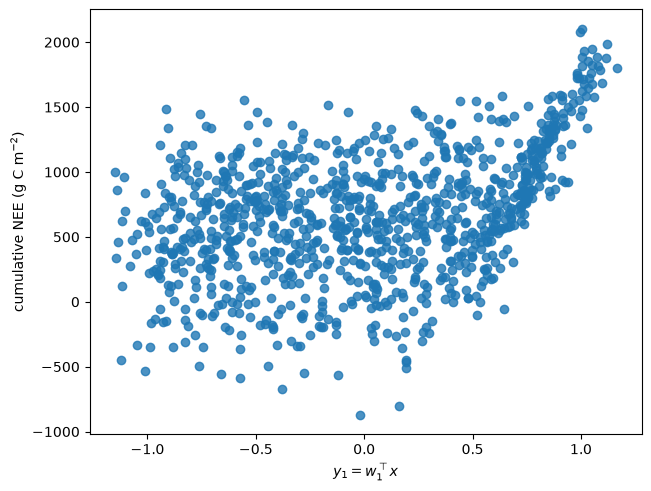

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(s, X=X, f=f[q], dims=1,
                                              qoi_label='cumulative NEE (g C m$^{-2}$)')
fig

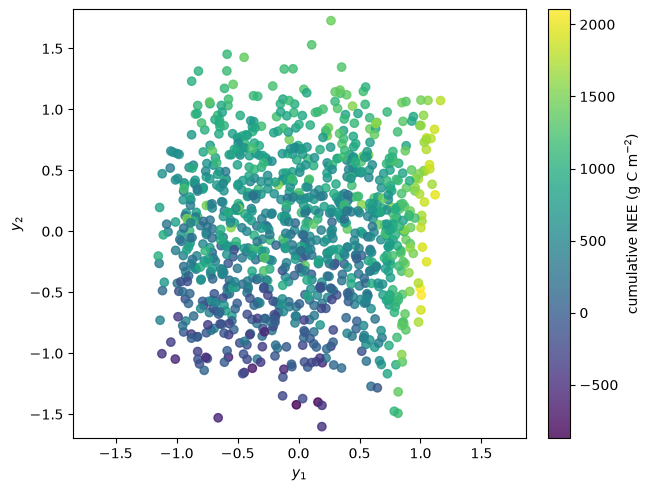

In [10]:
s2 = ac.with_dimension(s, 2)
fig, ax = ac.plotting.plot_sufficient_summary(s2, X=X, f=f[q], dims=2,
                                              qoi_label='cumulative NEE (g C m$^{-2}$)')
fig

In [11]:
r2 = {}
for n in (1, 2, 3, 4):
    for deg in (2, 3):
        sur = ac.fit_surrogate(X=X, f=f[q], space=space, subspace=ac.with_dimension(s, n),
                               kind='poly', degree=deg)
        r2[(n, deg)] = sur.loo_r_squared
full = ac.fit_surrogate(X=X, f=f[q], space=space, subspace=None, kind='poly', degree=2)
print('leave-one-out R^2 of polynomial surrogates on the first n active variables:')
for (n, deg), v in r2.items():
    print(f'  n = {n}, degree {deg}: {v:.3f}')
print(f'  all 8 inputs, degree 2: {full.loo_r_squared:.3f}')
r2_nee = r2

leave-one-out R^2 of polynomial surrogates on the first n active variables:
  n = 1, degree 2: 0.260
  n = 1, degree 3: 0.313
  n = 2, degree 2: 0.607
  n = 2, degree 3: 0.685
  n = 3, degree 2: 0.741
  n = 3, degree 3: 0.837
  n = 4, degree 2: 0.850
  n = 4, degree 3: 0.928
  all 8 inputs, degree 2: 0.861


The one-dimensional summary plot shows a trend in $\mathbf w_1^T\mathbf x$ (NEE rises steeply toward the right, where `psnTOpt` is low) but a wide spread around it: a cubic in $\mathbf w_1^T\mathbf x$ has leave-one-out $R^2 = 0.313$. Two active variables raise it to 0.685, three to 0.837 and four to 0.928 (cubic), above a full quadratic in all eight inputs (0.861). So cumulative NEE has a dominant direction but no low-dimensional active subspace in the strict sense; about four dimensions are needed for an accurate response surface.

## Results: total evapotranspiration

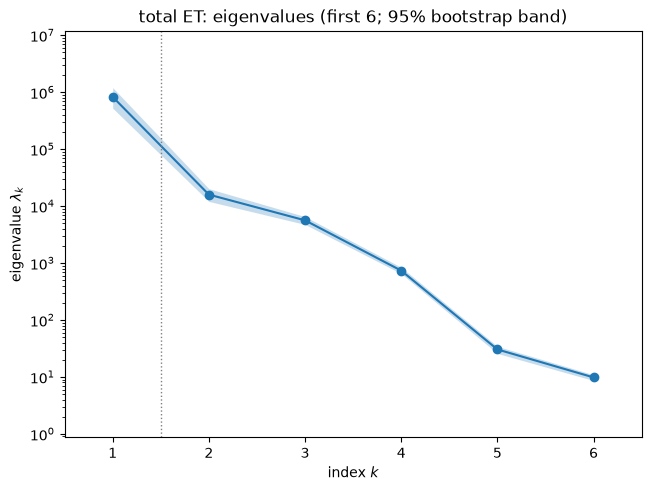

In [12]:
q = 'total_et'
s = subs[q]
fig, ax = ac.plotting.plot_eigenvalues(s, k_max=6)
ax.set_title('total ET: eigenvalues (first 6; 95% bootstrap band)')
fig

lambda_1/lambda_2 = 51.9 (bootstrap 95% interval of lambda_1: 5.240e+05 to 1.203e+06; lambda_2: 1.207e+04 to 2.022e+04)


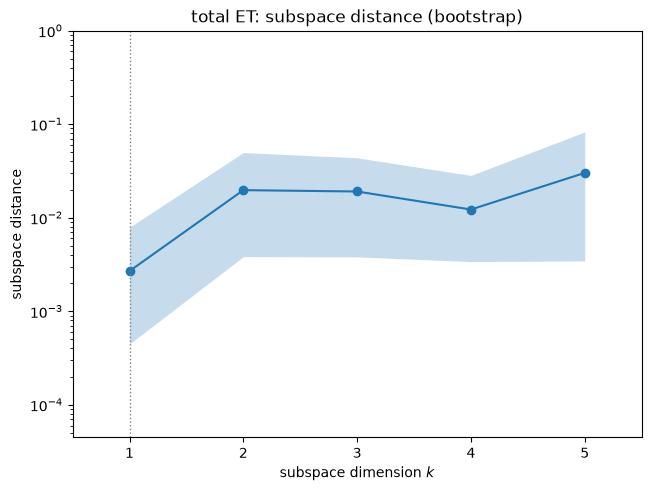

In [13]:
fig, ax = ac.plotting.plot_subspace_errors(s, k_max=5)
ax.set_title('total ET: subspace distance (bootstrap)')
lo, hi = ac.bootstrap_interval(s.bootstrap_eigenvalues)
print(f'lambda_1/lambda_2 = {s.eigenvalues[0] / s.eigenvalues[1]:.1f} '
      f'(bootstrap 95% interval of lambda_1: {lo[0]:.3e} to {hi[0]:.3e}; '
      f'lambda_2: {lo[1]:.3e} to {hi[1]:.3e})')
fig

w1: baseSoilResp -0.000, soilRespQ10 -0.000, soilWHC +1.000, halfSatPar -0.003, dVpdSlope -0.002, leafGrowth +0.011, psnTOpt +0.006, leafTurnoverRate -0.002
w2: baseSoilResp -0.000, soilRespQ10 -0.000, soilWHC -0.006, halfSatPar -0.025, dVpdSlope +0.001, leafGrowth +0.052, psnTOpt +0.998, leafTurnoverRate -0.023
activity scores, fraction of total: baseSoilResp 0.000, soilRespQ10 0.000, soilWHC 0.974, halfSatPar 0.001, dVpdSlope 0.000, leafGrowth 0.006, psnTOpt 0.019, leafTurnoverRate 0.000


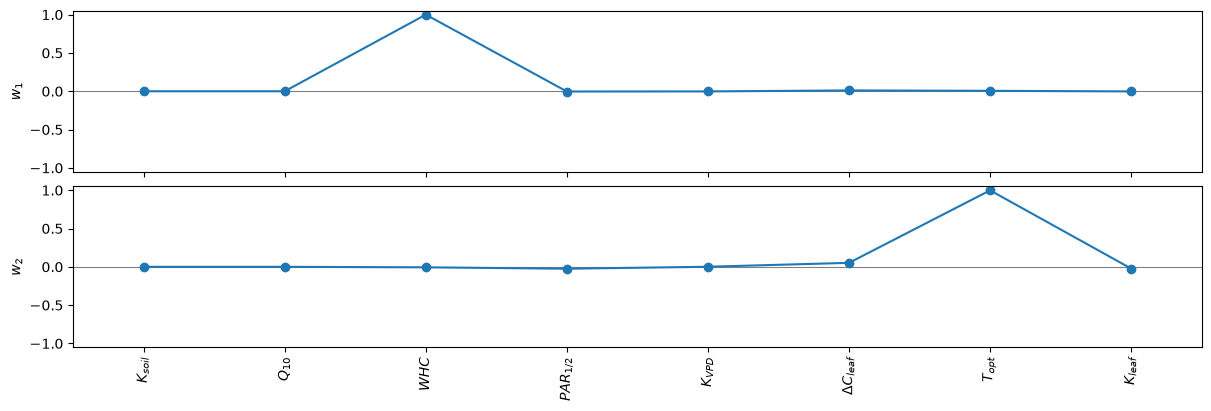

In [14]:
fig, axes = ac.plotting.plot_eigenvectors(s, indices=[0, 1], labels=labels, figsize=(12, 4))
act = ac.activity_scores(s, n=m)
act_et = act / act.sum()
print('w1:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(names, s.W[:, 0])))
print('w2:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(names, s.W[:, 1])))
print('activity scores, fraction of total:', ', '.join(f'{n} {a:.3f}' for n, a in zip(names, act_et)))
fig

leave-one-out R^2: n = 1, degree 2: 0.889, n = 1, degree 3: 0.917, n = 1, degree 4: 0.929, n = 2, degree 2: 0.898, n = 2, degree 3: 0.930, n = 2, degree 4: 0.944


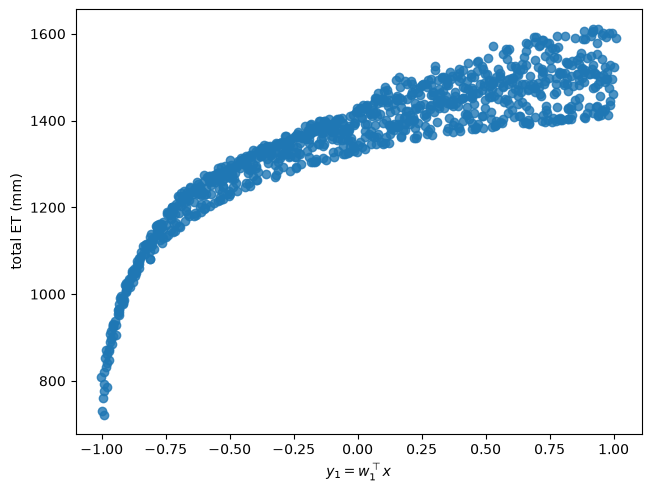

In [15]:
fig, ax = ac.plotting.plot_sufficient_summary(s, X=X, f=f[q], dims=1, qoi_label='total ET (mm)')
r2_et = {}
for n in (1, 2):
    for deg in (2, 3, 4):
        r2_et[(n, deg)] = ac.fit_surrogate(X=X, f=f[q], space=space, subspace=ac.with_dimension(s, n),
                                           kind='poly', degree=deg).loo_r_squared
print('leave-one-out R^2:', ', '.join(f'n = {n}, degree {d}: {v:.3f}' for (n, d), v in r2_et.items()))
fig

Total ET has a one-dimensional active subspace: $\lambda_1/\lambda_2 = 51.9$, and $\mathbf w_1$ is essentially the `soilWHC` axis (component 1.000; activity-score fraction 0.974). The summary plot is a saturating curve: ET rises steeply with the bucket size at small `soilWHC` and levels off; the scatter is tight on the left and widens on the right, where the second direction (mostly `psnTOpt`) matters. A quartic in the first active variable has leave-one-out $R^2 = 0.929$; adding the second (mostly `psnTOpt`) raises it only to 0.944.

### Surrogate fit for total ET

quartic in w1^T x: leave-one-out R^2 = 0.929


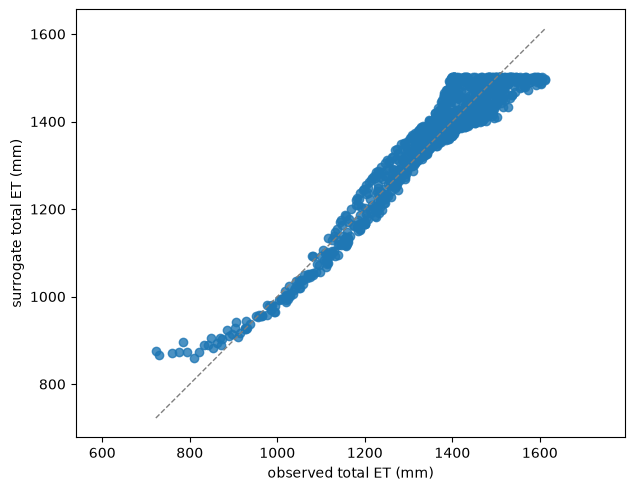

In [16]:
sur_et = ac.fit_surrogate(X=X, f=f['total_et'], space=space, subspace=ac.with_dimension(subs['total_et'], 1),
                          kind='poly', degree=4)
fig, ax = ac.plotting.plot_surrogate_fit(sur_et, X=X, f=f['total_et'], qoi_label='total ET (mm)')
print(f'quartic in w1^T x: leave-one-out R^2 = {sur_et.loo_r_squared:.3f}')
fig

## Total GPP (summary only)

GPP behaves like NEE: its first eigenvector is again almost `psnTOpt`, and it needs several dimensions.

In [17]:
s = subs['total_gpp']
lam = s.eigenvalues
act = ac.activity_scores(s, n=m)
print(f'total_gpp: lambda_1/lambda_2 = {lam[0]/lam[1]:.2f}, lambda_2/lambda_3 = {lam[1]/lam[2]:.2f}; '
      f'w1 psnTOpt {s.W[6, 0]:+.3f}; activity fractions: '
      + ', '.join(f'{n} {a:.3f}' for n, a in zip(names, act / act.sum()) if a > 0.01))
for n in (1, 2, 4):
    v = ac.fit_surrogate(X=X, f=f['total_gpp'], space=space, subspace=ac.with_dimension(s, n),
                         kind='poly', degree=3).loo_r_squared
    print(f'  cubic on n = {n} active variables: LOO R^2 = {v:.3f}')

total_gpp: lambda_1/lambda_2 = 2.66, lambda_2/lambda_3 = 1.32; w1 psnTOpt +0.997; activity fractions: soilWHC 0.206, halfSatPar 0.027, leafGrowth 0.172, psnTOpt 0.584
  cubic on n = 1 active variables: LOO R^2 = 0.159
  cubic on n = 2 active variables: LOO R^2 = 0.568
  cubic on n = 4 active variables: LOO R^2 = 0.918


## Comparison with the paper

The paper has no active-subspace or gradient results. Its closest quantities are the partial variances of PEcAn's uncertainty analysis (Fig. 2a), which ranked the SIPNET parameters by their share of the predictive variance of NEE, LE and soil respiration at Bartlett; the paper does not say whether these were computed under the Table A2 uniform priors or under PEcAn's meta-analysis parameter distributions (an open question in the report). We compare them with our normalized activity scores (all eigenpairs). The Fig. 2a values are read from the bars (±0.03); they and our scores are different measures for different sites and distributions, so only the ranking is comparable.

In [18]:
fig2_nee = {'baseSoilResp': 0.30, 'psnTOpt': 0.47, 'soilRespQ10': 0.12, 'halfSatPar': 0.05}
fig2_le = {'psnTOpt': 0.14, 'soilWHC': 0.24, 'leafGrowth': 0.20, 'leafTurnoverRate': 0.13,
           'dVpdSlope': 0.11, 'halfSatPar': 0.10}
rank = lambda a: {names[j]: r + 1 for r, j in enumerate(np.argsort(-a))}
rn, re_ = rank(act_nee), rank(act_et)
rows = ['| parameter | Fig. 2a NEE | activity, cum. NEE (rank) | Fig. 2a LE | activity, total ET (rank) |',
        '|---|---|---|---|---|']
for j, n in enumerate(names):
    rows.append(f'| `{n}` | {fig2_nee.get(n, "not shown")} | {act_nee[j]:.3f} ({rn[n]}) | '
                f'{fig2_le.get(n, "not shown")} | {act_et[j]:.3f} ({re_[n]}) |')
display(Markdown('\n'.join(rows)))

| parameter | Fig. 2a NEE | activity, cum. NEE (rank) | Fig. 2a LE | activity, total ET (rank) |
|---|---|---|---|---|
| `baseSoilResp` | 0.3 | 0.081 (4) | not shown | 0.000 (8) |
| `soilRespQ10` | 0.12 | 0.002 (8) | not shown | 0.000 (7) |
| `soilWHC` | not shown | 0.152 (2) | 0.24 | 0.974 (1) |
| `halfSatPar` | 0.05 | 0.026 (5) | 0.1 | 0.001 (4) |
| `dVpdSlope` | not shown | 0.006 (6) | 0.11 | 0.000 (5) |
| `leafGrowth` | not shown | 0.122 (3) | 0.2 | 0.006 (3) |
| `psnTOpt` | 0.47 | 0.607 (1) | 0.14 | 0.019 (2) |
| `leafTurnoverRate` | not shown | 0.004 (7) | 0.13 | 0.000 (6) |

In [19]:
lam_n, lam_e = subs['cum_nee'].eigenvalues, subs['total_et'].eigenvalues
rows = ['| quantity | paper | notebook |', '|---|---|---|',
        f'| number of SIPNET model parameters | 8 (+1 likelihood bias), Sec. 2.3 | {m} (bias not a model input) |',
        '| priors | uniform, Table A2 | same (`baseSoilResp` read in 1/yr) |',
        f'| model runs | 729 emulator knots: 243 from a Latin hypercube, then 2 rounds of 243 drawn 90 % from the previous emulator posterior and 10 % from the prior (Sec. 2.1, Table 1) | {M} Latin hypercube samples x 17 runs |',
        '| SIPNET run time | about 5.5 s "per execution" (Sec. 2.3), "per MCMC iteration in PEcAn including model execution and writing and reading model outputs" (App. A2) | about 0.02 s per run (binary only) |',
        '| site, period, step | Bartlett, 2005-2006, half-hourly | Niwot Ridge driver, 2004-2005, half-daily |',
        f'| precipitation | about {BARTLETT_PRECIP} mm per year (App. A1) | {precip / 2:.0f} mm per year (driver) |',
        '| non-calibrated SIPNET parameters | Bartlett trait meta-analysis (PEcAn, BETYdb) | PEcAn `template.param_v2` values |',
        '| cold-season soil respiration | tied to `baseSoilResp` (x 0.25) and `soilRespQ10` in PEcAn\'s 2018 set-up; whether it was switched on is not stated | absent (removed in SIPNET v2) |',
        f'| net carbon sources | not reported | {(f["cum_nee"] > 0).sum()} of {M} samples |',
        '| top parameter for NEE | `psnTOpt` (Fig. 2a, about 0.47) | `psnTOpt` (activity fraction ' f'{act_nee[6]:.2f}) |',
        '| top parameter for LE / ET | `soilWHC` (Fig. 2a, about 0.24) | `soilWHC` (activity fraction ' f'{act_et[2]:.2f}) |',
        f'| eigenvalue ratios, cum. NEE | not reported | l1/l2 = {lam_n[0]/lam_n[1]:.2f}, l2/l3 = {lam_n[1]/lam_n[2]:.2f} |',
        f'| eigenvalue ratios, total ET | not reported | l1/l2 = {lam_e[0]/lam_e[1]:.1f}, l2/l3 = {lam_e[1]/lam_e[2]:.2f} |',
        f'| 1-D surrogate LOO R^2 (NEE / ET) | not reported | {r2_nee[(1, 3)]:.3f} (cubic) / {sur_et.loo_r_squared:.3f} (quartic) |']
display(Markdown('\n'.join(rows)))
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

| quantity | paper | notebook |
|---|---|---|
| number of SIPNET model parameters | 8 (+1 likelihood bias), Sec. 2.3 | 8 (bias not a model input) |
| priors | uniform, Table A2 | same (`baseSoilResp` read in 1/yr) |
| model runs | 729 emulator knots: 243 from a Latin hypercube, then 2 rounds of 243 drawn 90 % from the previous emulator posterior and 10 % from the prior (Sec. 2.1, Table 1) | 1000 Latin hypercube samples x 17 runs |
| SIPNET run time | about 5.5 s "per execution" (Sec. 2.3), "per MCMC iteration in PEcAn including model execution and writing and reading model outputs" (App. A2) | about 0.02 s per run (binary only) |
| site, period, step | Bartlett, 2005-2006, half-hourly | Niwot Ridge driver, 2004-2005, half-daily |
| precipitation | about 1300 mm per year (App. A1) | 747 mm per year (driver) |
| non-calibrated SIPNET parameters | Bartlett trait meta-analysis (PEcAn, BETYdb) | PEcAn `template.param_v2` values |
| cold-season soil respiration | tied to `baseSoilResp` (x 0.25) and `soilRespQ10` in PEcAn's 2018 set-up; whether it was switched on is not stated | absent (removed in SIPNET v2) |
| net carbon sources | not reported | 902 of 1000 samples |
| top parameter for NEE | `psnTOpt` (Fig. 2a, about 0.47) | `psnTOpt` (activity fraction 0.61) |
| top parameter for LE / ET | `soilWHC` (Fig. 2a, about 0.24) | `soilWHC` (activity fraction 0.97) |
| eigenvalue ratios, cum. NEE | not reported | l1/l2 = 3.67, l2/l3 = 1.16 |
| eigenvalue ratios, total ET | not reported | l1/l2 = 51.9, l2/l3 = 2.83 |
| 1-D surrogate LOO R^2 (NEE / ET) | not reported | 0.313 (cubic) / 0.929 (quartic) |

notebook run time: 4.4 s


The top parameter agrees for both carbon and water: `psnTOpt` for NEE and `soilWHC` for LE/ET. Beyond that the rankings differ. In Fig. 2a `baseSoilResp` (SOM respiration rate) is second for NEE with about 0.30, while here it is fourth (activity-score fraction 0.081); with the paper's small initial soil pool (1600 g C m⁻²) and the cold driver, soil respiration is a small part of NEE here. A second candidate cause is structural: in the paper's SIPNET build the two calibrated soil parameters probably also set the cold-season soil respiration (see the model section), a channel that SIPNET v2 does not have, so `baseSoilResp` may matter more for annual NEE there. For LE, Fig. 2a spreads the variance over six parameters, while here `soilWHC` dominates total ET (activity-score fraction 0.974); a two-year total under a dry, cold climate is controlled more by the size of the soil bucket than half-hourly LE at a moist site. These differences may come from the site and its climate (most samples here are net carbon sources), the non-calibrated parameter values, the cold-season soil respiration, the time aggregation, the distributions or the measure; we cannot separate them without the paper's Bartlett set-up.

## References

1. I. Fer, R. Kelly, P. R. Moorcroft, A. D. Richardson, E. M. Cowdery, and M. C. Dietze. Linking big models to big data: efficient ecosystem model calibration through Bayesian model emulation. *Biogeosciences* 15(19):5801–5830, 2018. [doi:10.5194/bg-15-5801-2018](https://doi.org/10.5194/bg-15-5801-2018)
2. B. H. Braswell, W. J. Sacks, E. Linder, and D. S. Schimel. Estimating diurnal to annual ecosystem parameters by synthesis of a carbon flux model with eddy covariance net ecosystem exchange observations. *Global Change Biology* 11(2):335–355, 2005. [doi:10.1111/j.1365-2486.2005.00897.x](https://doi.org/10.1111/j.1365-2486.2005.00897.x)
3. W. J. Sacks, D. S. Schimel, R. K. Monson, and B. H. Braswell. Model-data synthesis of diurnal and seasonal CO2 fluxes at Niwot Ridge, Colorado. *Global Change Biology* 12(2):240–259, 2006. [doi:10.1111/j.1365-2486.2005.01059.x](https://doi.org/10.1111/j.1365-2486.2005.01059.x)
4. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
5. SIPNET, github.com/PecanProject/sipnet (BSD 3-clause), v2.2.0-11, commit c3479bd681ad092e6be33fcf14272e23e0b3fcbf. PEcAn, github.com/PecanProject/pecan (BSD 3-clause), commit 22ab2838613129f2c02c936f0fea29582aefc17c.

## Acknowledgments

From the paper: I. Fer was funded by grants to M. C. Dietze from the NSF Macrosystems program (nos. 1318164, 1241891) and NASA Terrestrial Ecosystems. The PEcAn project is supported by the NSF (ABI no. 1062547, ABI no. 1458021, DIBBS no. 1261582), NASA Terrestrial Ecosystems, the Energy Biosciences Institute, and an Amazon AWS education grant. Research at the Bartlett Experimental Forest is supported by the USDA Forest Service's Northern Research Station; additional support came from the NSF (DEB no. 1114804), the Northeastern States Research Cooperative, and DOE NICCR grant DE-FC02-06ER64157 to P. R. Moorcroft.